# F1 EDA - is the race decided on saturday?

Majed Alotaibi | Tuwaiq Academy | Unit 3 Final Project

# Step 1 - Dataset

**Title:** Formula 1 World Championship (1950-2020) by Rohan Rao

**Source:** https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020

**Description:** every F1 race since 1950, from the Ergast API. it comes as 14 csv files (results, races, drivers, constructors...). the title says 2020 but the data actually goes to the end of 2024

**Why i chose it:** i watch every F1 race so i wanted to work on something i actually like :) also the data is split into many tables so i get to practice merging and cleaning

# Step 2 - Problem Definition

**what is the dataset about?** the result of every driver in every race. where they started, where they finished, and why they retired if they didnt finish

**main question:** is the race decided on saturday? basically does qualifying (the grid position) decide who wins on sunday

**other questions:**
1. how strong is grid vs finish since 2010?
2. does one team win everything in each era?
3. are the cars more reliable now?

**what i expect:** pole wins most of the races, every era has one team that dominates, and there are less DNFs now than before

for grid vs finish i only use 2010-2024 because the old cars and rules were too different

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Step 3 - Data Loading & Structure

In [2]:
print(len(os.listdir('../data/raw')))
# 14 csv files in the dataset, i start with results
results_raw=pd.read_csv('../data/raw/results.csv')
results_raw.head()

14


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


In [3]:
results_raw.shape
# 26759 rows and 18 columns

(26759, 18)

In [4]:
results_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26759 non-null  object 
 5   grid             26759 non-null  int64  
 6   position         26759 non-null  object 
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             26759 non-null  object 
 12  milliseconds     26759 non-null  object 
 13  fastestLap       26759 non-null  object 
 14  rank             26759 non-null  object 
 15  fastestLapTime   26759 non-null  object 
 16  fastestLapSpeed  26759 non-null  object 
 17  statusId    

In [5]:
results_raw.describe()

,resultId,raceId,driverId,constructorId,grid,positionOrder,points,laps,statusId
count,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000
mean,13380.977391,551.687283,278.673530,50.180537,11.134796,12.794051,1.987632,46.301768,17.224971
std,7726.134642,313.265036,282.703039,61.551498,7.202860,7.665951,4.351209,29.496557,26.026104
min,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000
25%,6690.500000,300.000000,57.000000,6.000000,5.000000,6.000000,0.000000,23.000000,1.000000
50%,13380.000000,531.000000,172.000000,25.000000,11.000000,12.000000,0.000000,53.000000,10.000000
75%,20069.500000,811.000000,399.500000,63.000000,17.000000,18.000000,2.000000,66.000000,14.000000
max,26764.000000,1144.000000,862.000000,215.000000,34.000000,39.000000,50.000000,200.000000,141.000000


In [6]:
results_raw.isnull().sum()
# no missing values?? but position and milliseconds are object and not numbers, weird

resultId           0
raceId             0
driverId           0
constructorId      0
number             0
grid               0
position           0
positionText       0
positionOrder      0
points             0
laps               0
time               0
milliseconds       0
fastestLap         0
rank               0
fastestLapTime     0
fastestLapSpeed    0
statusId           0
dtype: int64

In [7]:
results_raw['position'].value_counts().head()
# thats why, the missing values are written as \N so pandas doesnt see them as missing

position
\N    10953
3      1135
4      1135
2      1133
5      1131
Name: count, dtype: int64

## merging the tables
read the files again with na_values so \N becomes NaN, then merge them on the id columns

In [8]:
results=pd.read_csv('../data/raw/results.csv', na_values=['\\N'])
races=pd.read_csv('../data/raw/races.csv', na_values=['\\N'])
drivers=pd.read_csv('../data/raw/drivers.csv', na_values=['\\N'])
constructors=pd.read_csv('../data/raw/constructors.csv', na_values=['\\N'])
status=pd.read_csv('../data/raw/status.csv', na_values=['\\N'])
circuits=pd.read_csv('../data/raw/circuits.csv', na_values=['\\N'])

In [9]:
# only keep the columns i need from each table
races=races[['raceId', 'year', 'round', 'circuitId', 'name', 'date']]
drivers=drivers[['driverId', 'forename', 'surname', 'nationality']]
constructors=constructors[['constructorId', 'name', 'nationality']]
circuits=circuits[['circuitId', 'name', 'country']]

df=results.merge(races, on='raceId')
df=df.merge(drivers, on='driverId')
df=df.merge(constructors, on='constructorId')
df=df.merge(status, on='statusId')
df=df.merge(circuits, on='circuitId')
df.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,...,name_x,date,forename,surname,nationality_x,name_y,nationality_y,status,name,country
0,1,18,1,1,22.0,1,1.0,1,1,10.0,...,Australian Grand Prix,2008-03-16,Lewis,Hamilton,British,McLaren,British,Finished,Albert Park Grand Prix Circuit,Australia
1,2,18,2,2,3.0,5,2.0,2,2,8.0,...,Australian Grand Prix,2008-03-16,Nick,Heidfeld,German,BMW Sauber,German,Finished,Albert Park Grand Prix Circuit,Australia
2,3,18,3,3,7.0,7,3.0,3,3,6.0,...,Australian Grand Prix,2008-03-16,Nico,Rosberg,German,Williams,British,Finished,Albert Park Grand Prix Circuit,Australia
3,4,18,4,4,5.0,11,4.0,4,4,5.0,...,Australian Grand Prix,2008-03-16,Fernando,Alonso,Spanish,Renault,French,Finished,Albert Park Grand Prix Circuit,Australia
4,5,18,5,1,23.0,3,5.0,5,5,4.0,...,Australian Grand Prix,2008-03-16,Heikki,Kovalainen,Finnish,McLaren,British,Finished,Albert Park Grand Prix Circuit,Australia


In [10]:
df.shape
# still 26759 rows so the merge didnt lose anything

(26759, 31)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 31 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26753 non-null  float64
 5   grid             26759 non-null  int64  
 6   position         15806 non-null  float64
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             7680 non-null   object 
 12  milliseconds     7680 non-null   float64
 13  fastestLap       8252 non-null   float64
 14  rank             8510 non-null   float64
 15  fastestLapTime   8252 non-null   object 
 16  fastestLapSpeed  8252 non-null   float64
 17  statusId    

In [12]:
df.describe()

,resultId,raceId,driverId,constructorId,number,grid,position,positionOrder,points,laps,milliseconds,fastestLap,rank,fastestLapSpeed,statusId,year,round,circuitId
count,26759.000000,26759.000000,26759.000000,26759.000000,26753.000000,26759.000000,15806.000000,26759.000000,26759.000000,26759.000000,7.680000e+03,8252.000000,8510.000000,8252.000000,26759.000000,26759.000000,26759.000000,26759.000000
mean,13380.977391,551.687283,278.673530,50.180537,18.153927,11.134796,8.020499,12.794051,1.987632,46.301768,6.185833e+06,42.732913,10.334313,204.116330,17.224971,1991.394372,8.511192,23.820808
std,7726.134642,313.265036,282.703039,61.551498,15.581135,7.202860,4.840796,7.665951,4.351209,29.496557,1.669306e+06,16.603460,6.140957,21.377265,26.026104,19.952885,5.070231,19.112002
min,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,5.260000e+02,1.000000,0.000000,89.540000,1.000000,1950.000000,1.000000,1.000000
25%,6690.500000,300.000000,57.000000,6.000000,7.000000,5.000000,4.000000,6.000000,0.000000,23.000000,5.378454e+06,33.000000,5.000000,193.322500,1.000000,1977.000000,4.000000,9.000000
50%,13380.000000,531.000000,172.000000,25.000000,16.000000,11.000000,8.000000,12.000000,0.000000,53.000000,5.788194e+06,46.000000,10.000000,204.894000,10.000000,1991.000000,8.000000,18.000000
75%,20069.500000,811.000000,399.500000,63.000000,24.000000,17.000000,11.000000,18.000000,2.000000,66.000000,6.402676e+06,54.000000,15.000000,217.324000,14.000000,2009.000000,12.000000,34.000000
max,26764.000000,1144.000000,862.000000,215.000000,208.000000,34.000000,33.000000,39.000000,50.000000,200.000000,1.509054e+07,85.000000,24.000000,257.320000,141.000000,2024.000000,24.000000,80.000000


In [13]:
df.isnull().sum()

resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           10953
positionText           0
positionOrder          0
points                 0
laps                   0
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fastestLapSpeed    18507
statusId               0
year                   0
round                  0
circuitId              0
name_x                 0
date                   0
forename               0
surname                0
nationality_x          0
name_y                 0
nationality_y          0
status                 0
name                   0
country                0
dtype: int64

# Step 4 - Data Cleaning

## 1- Missing values

In [14]:
print(results_raw['position'].isnull().sum())
print(results['position'].isnull().sum())
print(results.isnull().sum())
# before na_values it was 0 missing, after it its 10953 in position
# position is empty when the driver didnt finish so thats normal
# i didnt drop them becuase the missing values make sense here

0
10953
resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           10953
positionText           0
positionOrder          0
points                 0
laps                   0
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fastestLapSpeed    18507
statusId               0
dtype: int64


In [15]:
print(df[df['milliseconds'].notna()]['status'].value_counts().head(3))
print(df[df['fastestLapTime'].notna()]['year'].min())
# time and milliseconds are almost only there for drivers who finished on the lead lap, lapped cars dont get a time
# fastest lap data only starts in 2004

status
Finished        7673
Disqualified       5
+1 Lap             1
Name: count, dtype: int64
2004


## 2- Keep 1950-2024

In [16]:
print(df['year'].min(), df['year'].max())
df=df[(df['year']>=1950)&(df['year']<=2024)]
df.shape
# the data already ends in 2024 so nothing got removed

1950 2024


(26759, 31)

## 3- Data types

In [17]:
df['position']=pd.to_numeric(df['position'], errors='coerce')
df['milliseconds']=pd.to_numeric(df['milliseconds'], errors='coerce')
df['fastestLapSpeed']=pd.to_numeric(df['fastestLapSpeed'], errors='coerce')
#df.dtypes
df[['position', 'milliseconds', 'fastestLapSpeed']].dtypes

position           float64
milliseconds       float64
fastestLapSpeed    float64
dtype: object

## 4- Fastest lap time to seconds

In [18]:
# lap time looks like 1:27.452 so i add 00: in front so to_timedelta works
df['fastest_lap_sec']=pd.to_timedelta('00:' + df['fastestLapTime']).dt.total_seconds()
df[['fastestLapTime', 'fastest_lap_sec']].dropna().head()

,fastestLapTime,fastest_lap_sec
0,1:27.452,87.452
1,1:27.739,87.739
2,1:28.090,88.090
3,1:28.603,88.603
4,1:27.418,87.418


## 5- Grid 0

In [19]:
print((df['grid']==0).sum())
print(df[df['grid']==0]['status'].value_counts().head())
# most grid 0 rows are drivers who didnt qualify or withdrew, the few that raced started from the pit lane
# i keep the rows but make a new column where 0 is NaN
df['grid_clean']=df['grid'].replace(0, np.nan)

1638
status
Did not qualify       1013
Did not prequalify     331
Withdrew               164
+1 Lap                  27
Finished                22
Name: count, dtype: int64


## 6- Rename columns

In [20]:
df.columns
# after merging, the name columns became name_x and name_y

Index(['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid',
       'position', 'positionText', 'positionOrder', 'points', 'laps', 'time',
       'milliseconds', 'fastestLap', 'rank', 'fastestLapTime',
       'fastestLapSpeed', 'statusId', 'year', 'round', 'circuitId', 'name_x',
       'date', 'forename', 'surname', 'nationality_x', 'name_y',
       'nationality_y', 'status', 'name', 'country', 'fastest_lap_sec',
       'grid_clean'],
      dtype='object')

In [21]:
df=df.rename(columns={'name_x': 'race_name', 'name_y': 'team', 'name': 'circuit_name',
                      'nationality_x': 'driver_nationality', 'nationality_y': 'team_nationality'})
df['driver']=df['forename'] + ' ' + df['surname']
df[['race_name', 'circuit_name', 'team', 'driver']].head()

,race_name,circuit_name,team,driver
0,Australian Grand Prix,Albert Park Grand Prix Circuit,McLaren,Lewis Hamilton
1,Australian Grand Prix,Albert Park Grand Prix Circuit,BMW Sauber,Nick Heidfeld
2,Australian Grand Prix,Albert Park Grand Prix Circuit,Williams,Nico Rosberg
3,Australian Grand Prix,Albert Park Grand Prix Circuit,Renault,Fernando Alonso
4,Australian Grand Prix,Albert Park Grand Prix Circuit,McLaren,Heikki Kovalainen


## 7- New columns

In [22]:
# finished = status is Finished or +1 Lap, +2 Laps... (lapped cars still finished the race)
df['finished']=(df['status']=='Finished') | (df['status'].str.contains('Lap'))

# these drivers never actually started
not_started=['Did not qualify', 'Did not prequalify', 'Withdrew', 'Did not start', 'Excluded', 'Not classified']
df['starter']=df['status'].isin(not_started)==False

# dnf = started but didnt finish
df['dnf']=(df['starter']==True) & (df['finished']==False)
df[['finished', 'starter', 'dnf']].sum()

finished    15161
starter     24975
dnf          9814
dtype: int64

In [23]:
df['status'].nunique()
# 137 different status labels!! too many so i put the DNFs into 3 groups

137

In [24]:
#print(df['status'].unique())
crash=['Accident', 'Collision', 'Collision damage', 'Spun off', 'Fatal accident',
       'Puncture', 'Tyre puncture', 'Damage', 'Debris']
other=['Retired', 'Disqualified', 'Illness', 'Injury', 'Injured', 'Physical', 'Driver unwell',
       'Eye injury', 'Safety concerns', 'Safety', 'Not restarted', '107% Rule', 'Underweight',
       'Out of fuel', 'Tyre', 'Fuel rig', 'Refuelling']

# everything else is mechanical (engine, gearbox, brakes...)
df['dnf_type']='Mechanical'
df.loc[df['status'].isin(crash), 'dnf_type']='Crash/collision'
df.loc[df['status'].isin(other), 'dnf_type']='Other'
df.loc[df['dnf']==False, 'dnf_type']=np.nan
df['dnf_type'].value_counts()

dnf_type
Mechanical         6503
Crash/collision    2819
Other               492
Name: count, dtype: int64

In [25]:
df['decade']=(df['year']//10)*10
df['podium']=df['positionOrder']<=3
df['win']=df['positionOrder']==1

## 8- Duplicates

In [26]:
print(df.duplicated().sum())
# no duplicates

0


## 9- Save the clean data

In [27]:
df=df[['resultId', 'raceId', 'year', 'round', 'date', 'race_name', 'circuitId', 'circuit_name', 'country',
       'driverId', 'driver', 'driver_nationality', 'constructorId', 'team', 'team_nationality',
       'grid', 'grid_clean', 'position', 'positionOrder', 'points', 'laps', 'milliseconds',
       'fastest_lap_sec', 'fastestLapSpeed', 'status', 'finished', 'starter', 'dnf', 'dnf_type',
       'decade', 'podium', 'win']]
df=df.sort_values(['year', 'round', 'positionOrder'])

df.to_csv('../data/clean_data.csv', index=False)
df.to_csv('../app/clean_data.csv', index=False)
df.shape

(26759, 32)

# Step 5 - EDA

modern = 2010-2024 and starters = drivers who actually started the race

In [28]:
modern=df[df['year']>=2010]
starters=df[df['starter']==True]
wins=df[df['win']==True]
print(modern.shape)
print(modern['raceId'].nunique())

(6436, 32)
305


## Univariate

### 1- how many laps do drivers usually complete? (histogram)

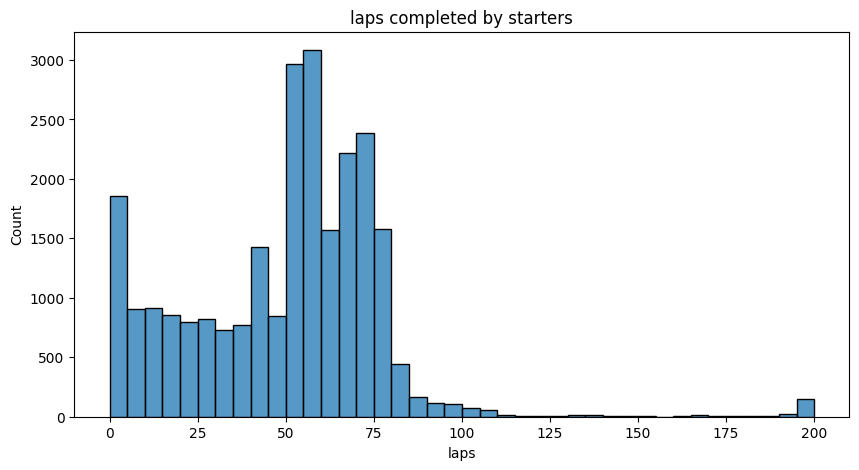

race_name
Indianapolis 500    224
Name: count, dtype: int64
1951 1960


In [29]:
plt.figure(figsize=(10,5))
sns.histplot(starters['laps'], bins=40)
plt.title('laps completed by starters')
plt.xlabel('laps')
plt.show()

long_races=starters[starters['laps']>150]
print(long_races['race_name'].value_counts())
print(long_races['year'].min(), long_races['year'].max())
# most races are 50-80 laps so most drivers are there
# the bar at 0 is drivers who retired on the first lap
# the ones near 200 are all the indy 500 races, from 1951 to 1960

### 2- which teams won the most races? (countplot)

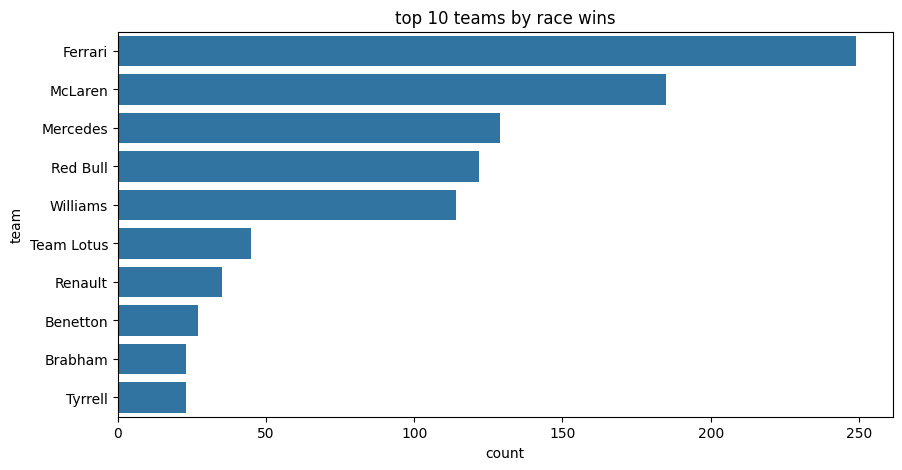

team
Ferrari       249
McLaren       185
Mercedes      129
Red Bull      122
Williams      114
Team Lotus     45
Renault        35
Benetton       27
Brabham        23
Tyrrell        23
Name: count, dtype: int64


In [30]:
top10_teams=wins['team'].value_counts().head(10).index

plt.figure(figsize=(10,5))
sns.countplot(y='team', data=wins[wins['team'].isin(top10_teams)], order=top10_teams)
plt.title('top 10 teams by race wins')
plt.show()
print(wins['team'].value_counts().head(10))
# ferrari has the most wins (249) then mclaren (185) and mercedes (129)

### 3- why do drivers retire? top 10 DNF reasons since 2010 (countplot)

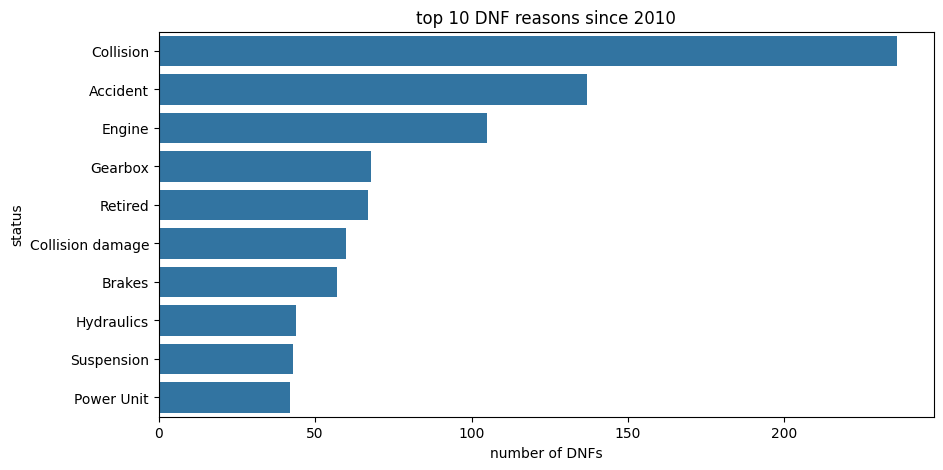

dnf_type
Mechanical         578
Crash/collision    467
Other               90
Name: count, dtype: int64


In [31]:
dnf_modern=modern[modern['dnf']==True]
top10_reasons=dnf_modern['status'].value_counts().head(10).index

plt.figure(figsize=(10,5))
sns.countplot(y='status', data=dnf_modern[dnf_modern['status'].isin(top10_reasons)], order=top10_reasons)
plt.title('top 10 DNF reasons since 2010')
plt.xlabel('number of DNFs')
plt.show()
print(dnf_modern['dnf_type'].value_counts())
# collision is number 1 on its own
# but engine, gearbox, brakes etc are all mechanical so together mechanical is more (578 vs 467 crashes)

### 4- points per race for the top teams since 2010 (boxplot)

Index(['Mercedes', 'Red Bull', 'Ferrari', 'McLaren', 'Force India',
       'Williams'],
      dtype='object', name='team')


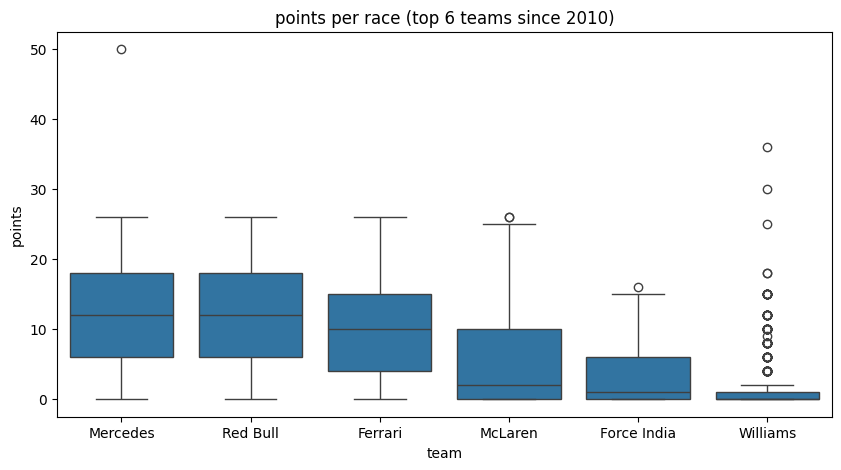

team
Ferrari        10.0
Force India     1.0
McLaren         2.0
Mercedes       12.0
Red Bull       12.0
Williams        0.0
Name: points, dtype: float64
       year             race_name          driver  points
22514  2014  Abu Dhabi Grand Prix  Lewis Hamilton    50.0


In [32]:
top_teams=modern.groupby('team')['points'].sum().sort_values(ascending=False).head(6).index
print(top_teams)

plt.figure(figsize=(10,5))
sns.boxplot(x='team', y='points', data=modern[modern['team'].isin(top_teams)], order=top_teams)
plt.title('points per race (top 6 teams since 2010)')
plt.show()
print(modern[modern['team'].isin(top_teams)].groupby('team')['points'].median())
print(modern[modern['points']>40][['year', 'race_name', 'driver', 'points']])
# mercedes and red bull have the highest median (12 points)
# force india's median is 1 and williams is 0 so they mostly get 0 or 1 point
# the outlier at 50 is hamilton in abu dhabi 2014, that race gave double points

## Bivariate & Multivariate

### 5- does where you start decide where you finish? (scatter)

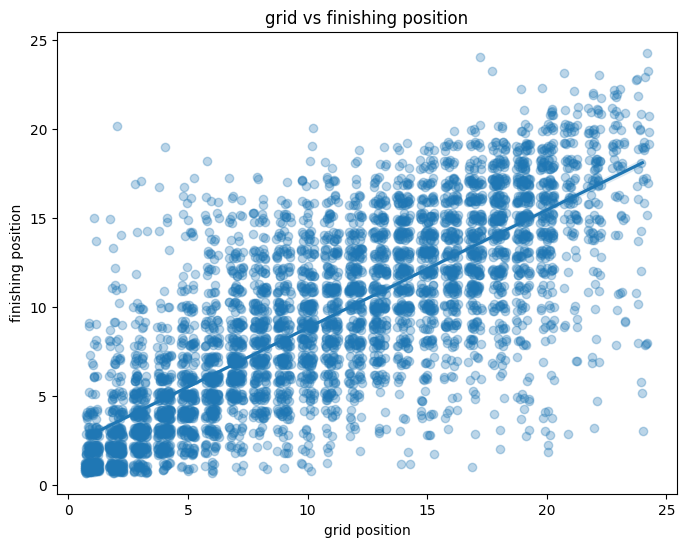

0.7777349534106459


In [33]:
finishers=modern[(modern['finished']==True)&(modern['grid_clean'].notna())]

plt.figure(figsize=(8,6))
sns.regplot(x='grid_clean', y='positionOrder', data=finishers, x_jitter=0.3, y_jitter=0.3, scatter_kws={'alpha': 0.3})
plt.title('grid vs finishing position')
plt.xlabel('grid position')
plt.ylabel('finishing position')
plt.show()
print(finishers['grid_clean'].corr(finishers['positionOrder']))
# 0.78 so its a strong positive relationship
# if you start at the back you almost never finish at the front

### 6- podium chance from each grid slot P1-P10 (bar plot)

grid_clean
1.0     80.0
2.0     69.0
3.0     51.0
4.0     35.0
5.0     20.0
6.0     14.0
7.0      8.0
8.0      3.0
9.0      4.0
10.0     4.0
Name: podium, dtype: float64


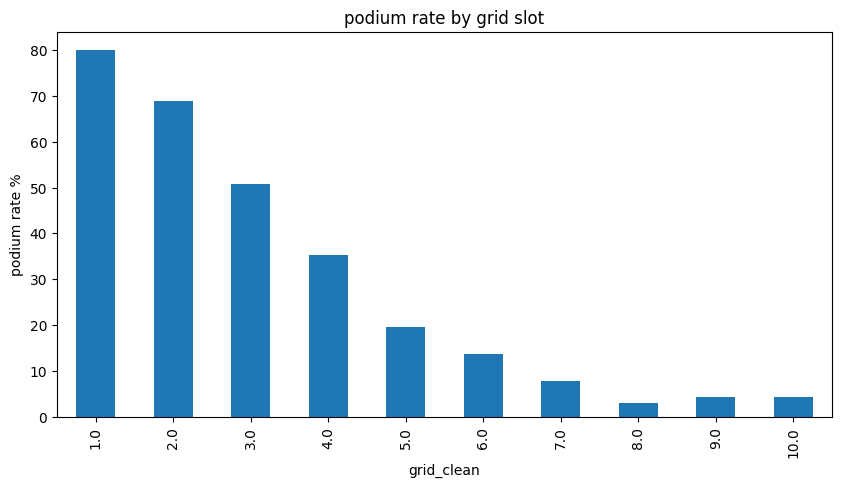

In [34]:
top10_grid=modern[modern['grid_clean']<=10]
podium_rate=top10_grid.groupby('grid_clean')['podium'].mean()*100
print(podium_rate.round())

podium_rate.plot(kind='bar', figsize=(10,5))
plt.title('podium rate by grid slot')
plt.ylabel('podium rate %')
plt.show()
# from pole its 80% and then it drops fast, P5 is only 20%

### 7- are cars more reliable now? DNF rate per decade (line plot)

In [35]:
starters=starters.copy()
starters['mechanical']=starters['dnf_type']=='Mechanical'

dnf_rate=starters.groupby('decade')['dnf'].mean()*100
mech_rate=starters.groupby('decade')['mechanical'].mean()*100
print(dnf_rate.round())
print(mech_rate.round())

decade
1950    49.0
1960    49.0
1970    47.0
1980    55.0
1990    50.0
2000    32.0
2010    19.0
2020    14.0
Name: dnf, dtype: float64
decade
1950    38.0
1960    41.0
1970    32.0
1980    38.0
1990    30.0
2000    19.0
2010    10.0
2020     6.0
Name: mechanical, dtype: float64


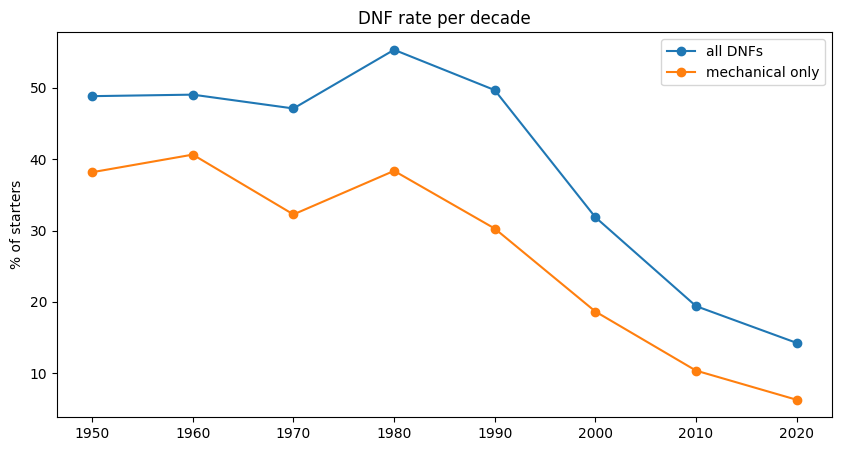

In [36]:
plt.figure(figsize=(10,5))
plt.plot(dnf_rate.index, dnf_rate, marker='o', label='all DNFs')
plt.plot(mech_rate.index, mech_rate, marker='o', label='mechanical only')
plt.title('DNF rate per decade')
plt.ylabel('% of starters')
plt.legend()
plt.show()
# until the 80s about half the starters didnt finish!! in the 2020s its only 14%
# mechanical DNFs went from 38% in the 1950s to 6%

### 8- which team was on top in every era? (bar plot)

In [37]:
eras=[('1950s', 1950, 1959), ('1960s', 1960, 1969), ('1970s', 1970, 1979), ('1980s', 1980, 1989),
      ('1990s', 1990, 1999), ('2000s', 2000, 2009), ('2010-13', 2010, 2013), ('2014-20', 2014, 2020),
      ('2021-24', 2021, 2024)]

era_names=[]
era_share=[]
for name, start, end in eras:
    era_wins=wins[(wins['year']>=start)&(wins['year']<=end)]
    top=era_wins['team'].value_counts(normalize=True).head(1)*100
    print(name, top.index[0], round(top.iloc[0]))
    era_names.append(name + ' ' + top.index[0])
    era_share.append(top.iloc[0])

1950s Ferrari 34
1960s Lotus-Climax 22
1970s Ferrari 26
1980s McLaren 36
1990s Williams 38
2000s Ferrari 49
2010-13 Red Bull 53
2014-20 Mercedes 74
2021-24 Red Bull 64


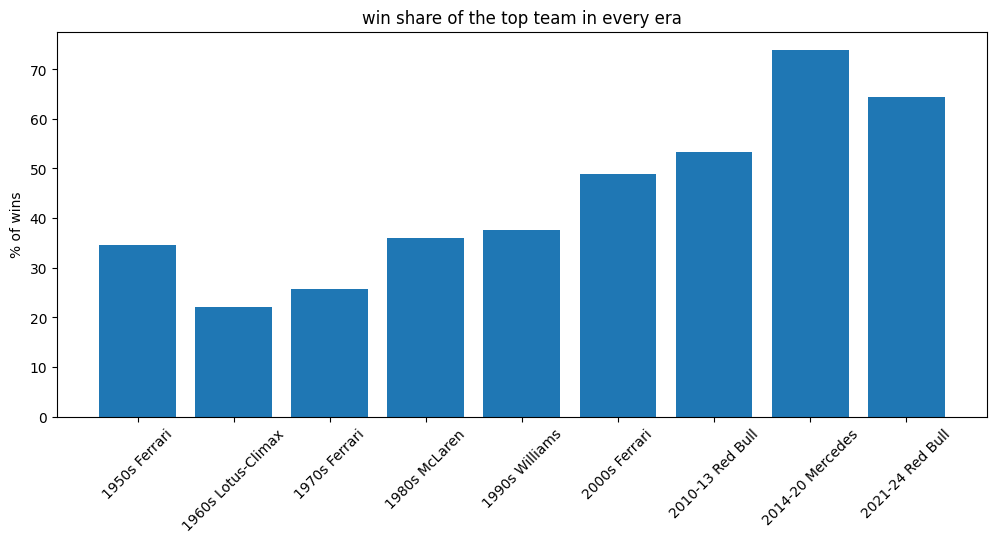

In [38]:
plt.figure(figsize=(12,5))
plt.bar(era_names, era_share)
plt.title('win share of the top team in every era')
plt.ylabel('% of wins')
plt.xticks(rotation=45)
plt.show()
# mercedes 2014-20 is the most dominant, 74% of the wins
# in the 60s and 70s the top team only had 22% and 26% so the wins were more spread out

### 9- correlation heatmap

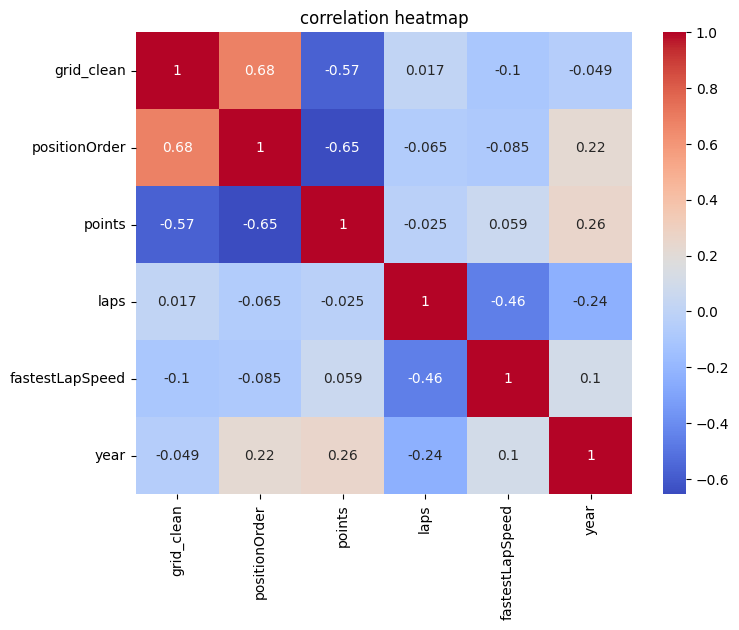

In [39]:
corr=df[df['finished']==True][['grid_clean', 'positionOrder', 'points', 'laps', 'fastestLapSpeed', 'year']].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('correlation heatmap')
plt.show()
# grid and finishing position is 0.68 here, lower than the 0.78 before because this is all the years not just 2010+
# points and position are -0.65 but thats normal because points come from the position
# year has almost no link with the result

### 10- where does each grid slot finish? (heatmap, 2010-2024)

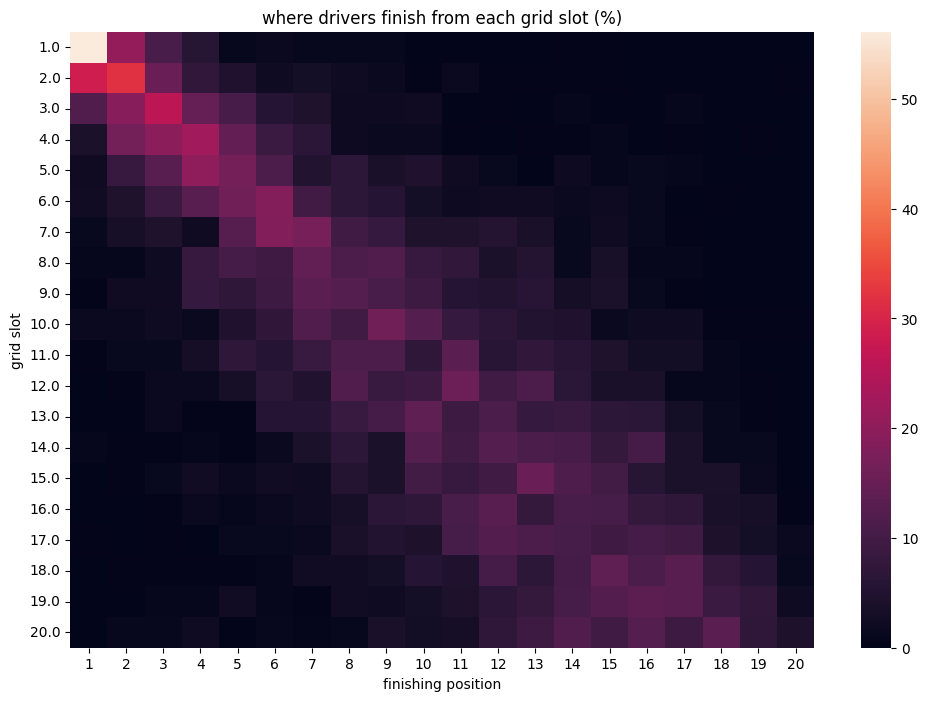

In [40]:
top20=finishers[(finishers['grid_clean']<=20)&(finishers['positionOrder']<=20)]
table=pd.crosstab(top20['grid_clean'], top20['positionOrder'], normalize='index')*100

plt.figure(figsize=(12,8))
sns.heatmap(table)
plt.title('where drivers finish from each grid slot (%)')
plt.xlabel('finishing position')
plt.ylabel('grid slot')
plt.show()
# the diagonal is the brightest so most drivers finish close to where they started

## checking the numbers for my slides

In [41]:
modern_wins=modern[modern['win']==True]

print('rows:', len(df))
print('races:', df['raceId'].nunique())
print('drivers:', df['driverId'].nunique())
print('teams:', df['constructorId'].nunique())
print('seasons:', df['year'].nunique())

rows: 26759
races: 1125
drivers: 861
teams: 211
seasons: 75


In [42]:
print('pole wins:', (modern_wins['grid_clean']==1).mean())
print('front row wins:', (modern_wins['grid_clean']<=2).mean())
print('wins from outside top 10:', (modern_wins['grid_clean']>10).sum())
print('within 3 places:', ((finishers['grid_clean']-finishers['positionOrder']).abs()<=3).mean())

pole wins: 0.5114754098360655
front row wins: 0.7704918032786885
wins from outside top 10: 4
within 3 places: 0.6667304747320061


In [43]:
print(modern[modern['dnf']==True]['dnf_type'].value_counts(normalize=True)*100)
print(wins[wins['year']==2023]['team'].value_counts().head(1))
print(df[df['year']==2023]['raceId'].nunique())
print(wins[(wins['year']>=2014)&(wins['year']<=2020)]['team'].value_counts().head(1))
print(df[(df['year']>=2014)&(df['year']<=2020)]['raceId'].nunique())
print(wins['driver'].value_counts().head(3))
print(df.groupby('decade')['grid'].max())

dnf_type
Mechanical         50.925110
Crash/collision    41.145374
Other               7.929515
Name: proportion, dtype: float64
team
Red Bull    21
Name: count, dtype: int64
22
team
Mercedes    102
Name: count, dtype: int64
138
driver
Lewis Hamilton        105
Michael Schumacher     91
Max Verstappen         63
Name: count, dtype: int64
decade
1950    34
1960    33
1970    31
1980    29
1990    28
2000    22
2010    24
2020    20
Name: grid, dtype: int64


In [44]:
# most numbers match my presentation
# within 3 places is 67% but the slides say 69%
# mechanical DNFs in the 1950s is 38% but the slides say 31%, its because here i count everything thats not a crash or other as mechanical

# Step 6 - Insights Summary

In [45]:
# patterns:
# qualifying matters a lot. since 2010 pole won 51% of the races and the front row won 77%
# only 4 out of 305 races were won from outside the top 10
# every era has a top team: ferrari in the 2000s, red bull 2010-13, mercedes 2014-20, then red bull again
# cars are way more reliable, about half the starters retired until the 80s and now its 14%

# relationships:
# grid vs finish correlation is 0.78 for finishers since 2010
# 2 out of 3 finishers end within 3 places of where they started
# podium chance drops really fast, 80% from P1 but 20% from P5
# since 2010, 51% of retirements are mechanical and 41% are crashes

# outliers:
# red bull won 21 of 22 races in 2023
# mercedes won 102 of 138 races from 2014 to 2020
# abu dhabi 2014 had double points so hamilton got 50 points in one race

# so is the race decided on saturday? not 100% but most of it yes

# Step 7 - Predictive Model (optional)

can i predict if a driver gets a podium from the grid, team and year? (2010-2024)

i compare it to a baseline that always says no podium

In [46]:
model_df=modern[(modern['starter']==True)&(modern['grid_clean'].notna())].copy()
# teams outside the top 6 go into 'Other'
model_df['team_group']=model_df['team']
model_df.loc[model_df['team'].isin(top_teams)==False, 'team_group']='Other'

X=model_df[['grid_clean', 'team_group', 'year']]
y=model_df['podium']
X=pd.get_dummies(X)
print(y.value_counts())
# only 14% are podiums so the classes are not balanced

podium
False    5423
True      915
Name: count, dtype: int64


In [47]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [48]:
# baseline that always says no podium
baseline=DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
y_base=baseline.predict(X_test)

print('Accuracy:', accuracy_score(y_test, y_base))
print('Precision:', precision_score(y_test, y_base, zero_division=0))
print('Recall:', recall_score(y_test, y_base))
print('F1:', f1_score(y_test, y_base))
print('ROC-AUC:', roc_auc_score(y_test, baseline.predict_proba(X_test)[:, 1]))

Accuracy: 0.8556782334384858
Precision: 0.0
Recall: 0.0
F1: 0.0
ROC-AUC: 0.5


In [49]:
model=LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred=model.predict(X_test)

print('Accuracy:', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall:', recall_score(y_test, y_pred))
print('F1:', f1_score(y_test, y_pred))
print('ROC-AUC:', roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]))
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9006309148264984
Precision: 0.708029197080292
Recall: 0.5300546448087432
F1: 0.60625
ROC-AUC: 0.9170305456926293
[[1045   40]
 [  86   97]]


In [50]:
# what if i only use the grid?
grid_model=LogisticRegression(max_iter=1000)
grid_model.fit(X_train[['grid_clean']], y_train)
print('ROC-AUC grid only:', roc_auc_score(y_test, grid_model.predict_proba(X_test[['grid_clean']])[:, 1]))
# the baseline gets 86% accuracy but it never predicts a podium, so accuracy alone means nothing here
# the logistic regression is way better, ROC-AUC is about 0.92
# with only the grid its 0.91, so the grid does most of the work

ROC-AUC grid only: 0.9088363425751051


# Step 8 - Final Summary

In [51]:
# main insights
# 1- grid position is the biggest factor, pole won about half the races since 2010
# 2- one team dominates almost every era
# 3- cars are way more reliable, DNFs went from about 50% to 14%

# what i learned
# how to merge tables with the id columns
# missing values are not always NaN, here they were \N and isnull() didnt catch them at first
# how to put 137 status labels into a few groups
# a model needs a baseline because accuracy can look good even when the model does nothing

# limitations
# the points system changed many times so i used positions and wins instead of points
# the status labels are not the same in every decade
# no weather, tyre or strategy data
# grids were diffrent sizes, the grid went up to 34 in the 50s and only 20 in the 2020s

# future work
# add the pit_stops and lap_times tables
# compare street circuits with normal tracks
# make the podium model better with more features